<a href="https://colab.research.google.com/github/Marietomaszekk/DAPR/blob/main/S4_FlippedClassroom_Exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64
From 344 penguins, 342 remain
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          342.00         342.00             342.00       342.00
mean             0.00          -0.00              -0.00         0.00
std              1.00           1.00               1.00         1.00
min             -2.17          -2.05              -2.06        -1.88
25%             -0.86          -0.79              -0.78        -0.81
50%              0.10           0.08              -0.28        -0.19
75%              0.84           0.79               0.86         0.68
max              2.88           2.21               2.14         2.62
[2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 0 2 2 2 2 2 0 2 2 2 0 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 0

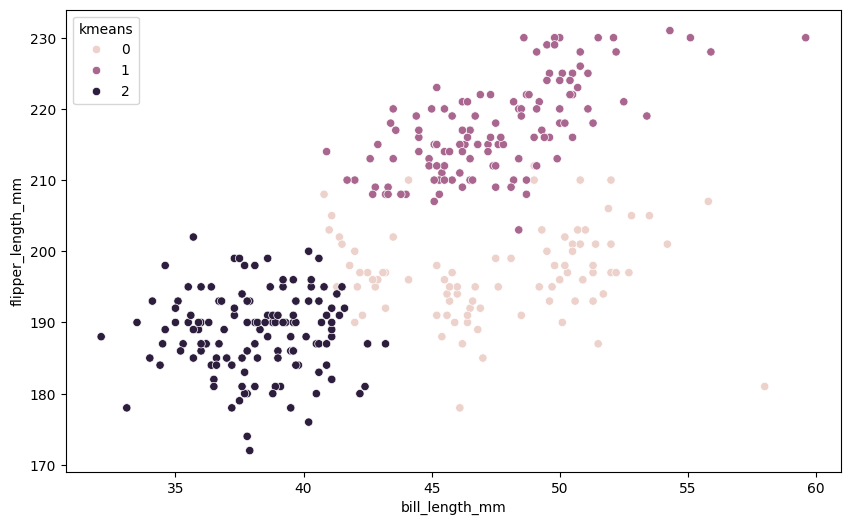

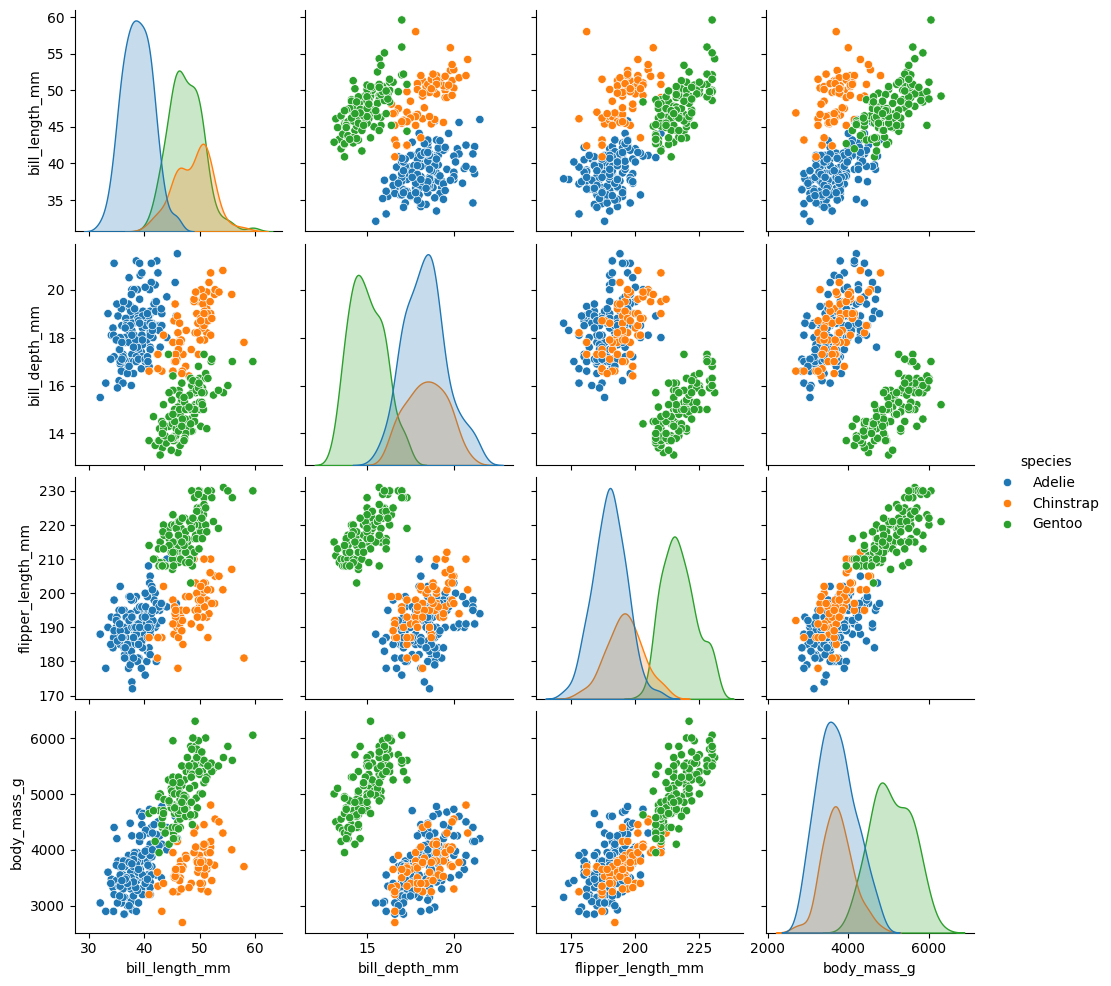

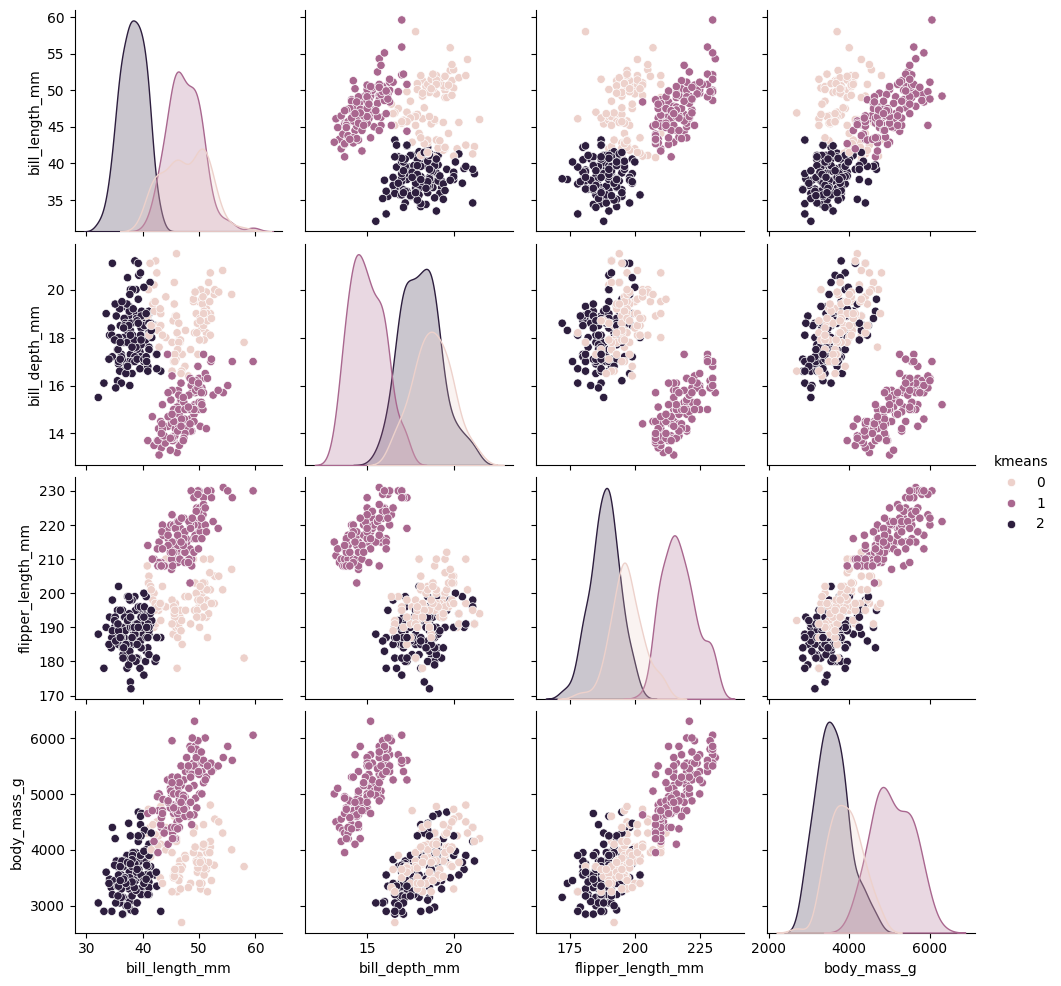

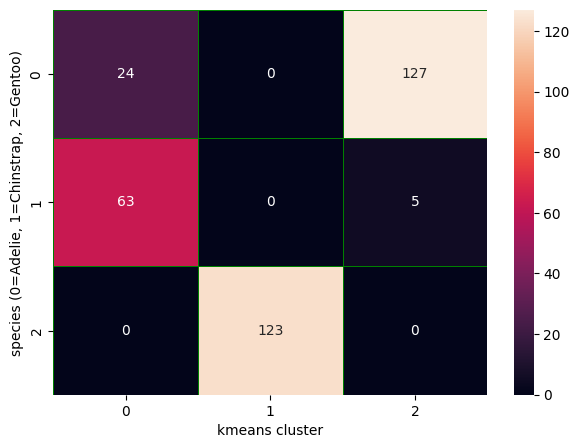

ARS with normalization: 0.7928369051321087
[[53  0 98]
 [22  0 46]
 [42 81  0]]
ARS without normalization: 0.3100937047458321


In [7]:

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) missing values
# I remove the penguins with empty values.
penguins_num = penguins[num_cols]
print(penguins_num.isna().sum())

penguins_clean = penguins.dropna(subset=num_cols)
print(penguins_clean[num_cols].isna().sum())
print('From {} penguins, {} remain'.format(penguins.shape[0], penguins_clean.shape[0]))

# b) normalization
# I scale the data because the weight has bigger numbers than the other columns.
scaler = StandardScaler()
penguins_scaled = scaler.fit_transform(penguins_clean[num_cols])
penguins_scaled_df = pd.DataFrame(penguins_scaled, columns=num_cols)
print(penguins_scaled_df.describe().round(2))

# c) k-means with 3 clusters
# I use 3 clusters because there are 3 species.
kmeans_labels = KMeans(n_clusters=3, random_state=42).fit_predict(penguins_scaled_df)
print(kmeans_labels)

# d) plots
# I compare the colors of the real species and the colors of k-means.
penguins_clean = penguins_clean.copy()
penguins_clean['kmeans'] = kmeans_labels

fig = plt.figure(figsize=(10,6))
sns.scatterplot(x='bill_length_mm', y='flipper_length_mm', hue='kmeans', data=penguins_clean)
plt.show()

sns.pairplot(penguins_clean, vars=num_cols, hue='species')
plt.show()

sns.pairplot(penguins_clean, vars=num_cols, hue='kmeans')
plt.show()

# e) confusion matrix and adjusted Rand score
# I check if the clusters are the same as the real species.
species_true = LabelEncoder().fit_transform(penguins_clean['species'])

cm = confusion_matrix(species_true, kmeans_labels)
fig = plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="green", fmt=".0f")
plt.xlabel("kmeans cluster")
plt.ylabel("species (0=Adelie, 1=Chinstrap, 2=Gentoo)")
plt.show()

ARS_kmeans = adjusted_rand_score(species_true, kmeans_labels)
print('ARS with normalization: {}'.format(ARS_kmeans))

# same k-means without normalization (for question f)
kmeans_labels_raw = KMeans(n_clusters=3, random_state=42).fit_predict(penguins_clean[num_cols])
print(confusion_matrix(species_true, kmeans_labels_raw))
ARS_kmeans_raw = adjusted_rand_score(species_true, kmeans_labels_raw)
print('ARS without normalization: {}'.format(ARS_kmeans_raw))

# f) interpretation
# With normalized data, k-means finds the 3 species quite well (ARS = 0.79, the best is 1).
# Gentoo penguins are all in the same group, so k-means finds them very well.
# Adelie and Chinstrap are a bit mixed: some Adelie are in the Chinstrap group.
# This is because these 2 species are very similar (same weight, same flipper size).
# They are different only in the length of the bill.
# Without normalization the ARS is only 0.31, so the result is much worse.
# This is because body_mass_g has very big numbers (like 4000),
# so k-means only looks at the weight and not at the other columns.

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

False
[[-1.         -0.23354968]
 [-1.          0.70064905]
 [-1.         -1.16774842]
 [ 1.          1.63484778]
 [ 1.          0.23354968]
 [ 1.         -1.16774842]]
5.656854249492381
5.656854249492381


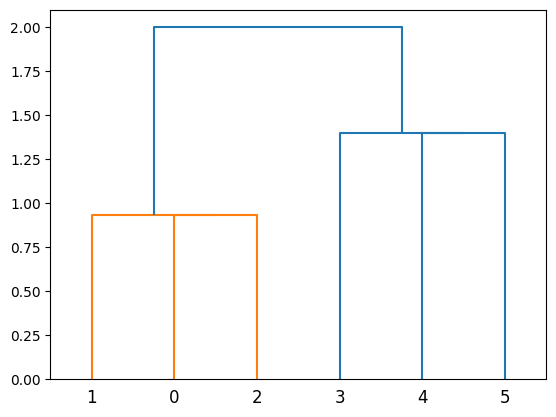

[1 1 1 0 0 0]
[0 0 0 1 1 1]


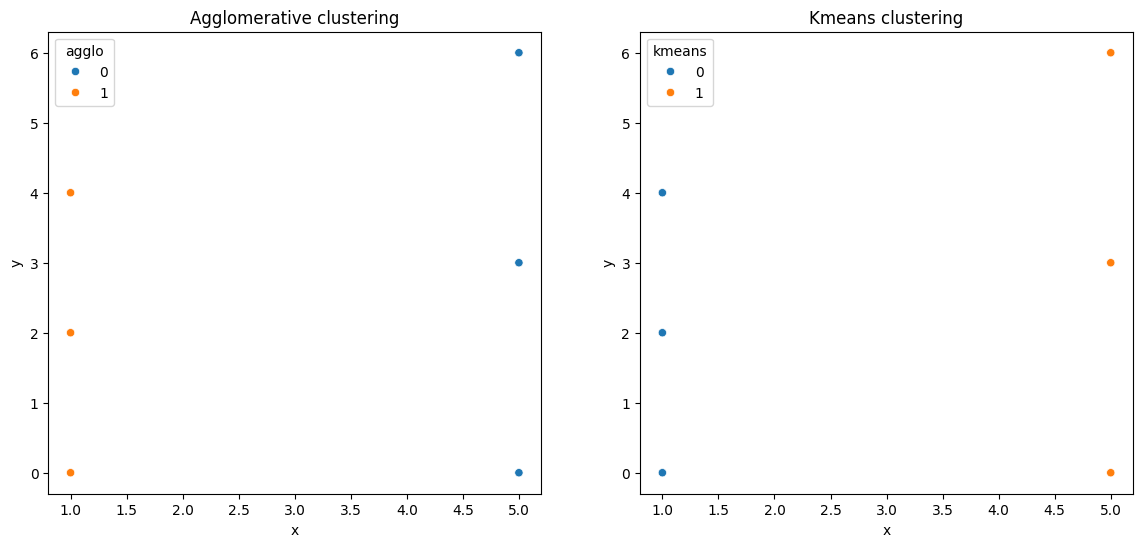

{1: 3, 0: 3}
{0: 3, 1: 3}


In [8]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) check for missing values
# False means there are no empty values.
print(np.isnan(X).any())

# b) normalize X
# I always scale the data before using distances.
X_scaled = StandardScaler().fit_transform(X)
print(X_scaled)

# c) euclidean distance with a for loop
# For each coordinate I add the difference squared, then I take the square root.
def euclidean_distance(p1, p2):
    total = 0
    for i in range(len(p1)):
        total = total + (p1[i] - p2[i]) ** 2
    return total ** 0.5

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

# d) agglomerative clustering + dendrogram
# The method joins the closest points step by step until there are 2 groups.
agglo_labels = AgglomerativeClustering(n_clusters=2).fit_predict(X_scaled)

Z = linkage(X_scaled)
dendrogram(Z)
plt.show()

# e) k-means with 2 clusters
# I do the same with k-means to compare.
kmeans_labels = KMeans(n_clusters=2, random_state=42).fit_predict(X_scaled)

# f) compare the two methods
# I put the two plots side by side.
print(agglo_labels)
print(kmeans_labels)

df1 = pd.DataFrame(X, columns=['x', 'y'])
df1['agglo'] = agglo_labels
df1['kmeans'] = kmeans_labels

fig = plt.figure(figsize=(14,6))
plt.subplot(1,2,1)
sns.scatterplot(x='x', y='y', hue='agglo', data=df1)
plt.title("Agglomerative clustering")
plt.subplot(1,2,2)
sns.scatterplot(x='x', y='y', hue='kmeans', data=df1)
plt.title("Kmeans clustering")
plt.show()

# g) count the points in each cluster with a dictionary
# For each point I add 1 to the count of its cluster.
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        label = int(label)
        if label in counts:
            counts[label] = counts[label] + 1
        else:
            counts[label] = 1
    return counts

print(cluster_sizes(agglo_labels))
print(cluster_sizes(kmeans_labels))

# The two methods find the same 2 groups: the 3 points with x=1 and the 3 points with x=5.
# The numbers 0 and 1 can be switched, but the groups are the same.
# This is normal because the 2 groups are far from each other.
# Each group has 3 points.

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

carat    0
depth    0
table    0
price    0
dtype: int64
Rows after dropna: 1000


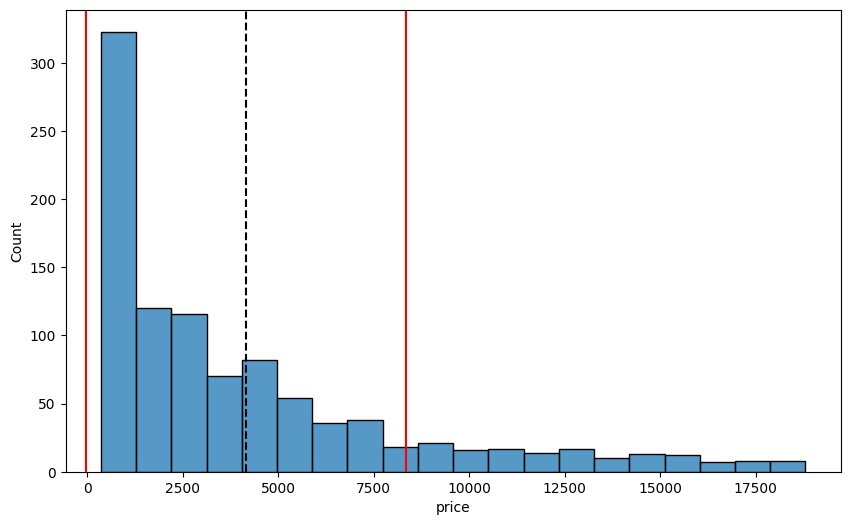

G = 1  BIC = 9270
G = 2  BIC = 7589
G = 3  BIC = 7125
G = 4  BIC = 6977
G = 5  BIC = 7014
G = 6  BIC = 6988
G = 7  BIC = 7047
G = 8  BIC = 7173


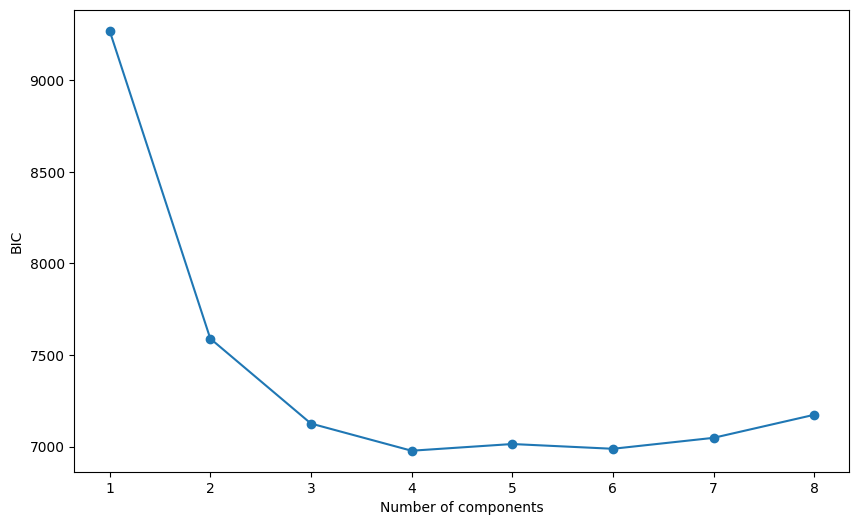

...and the winner is GMM model G = 4


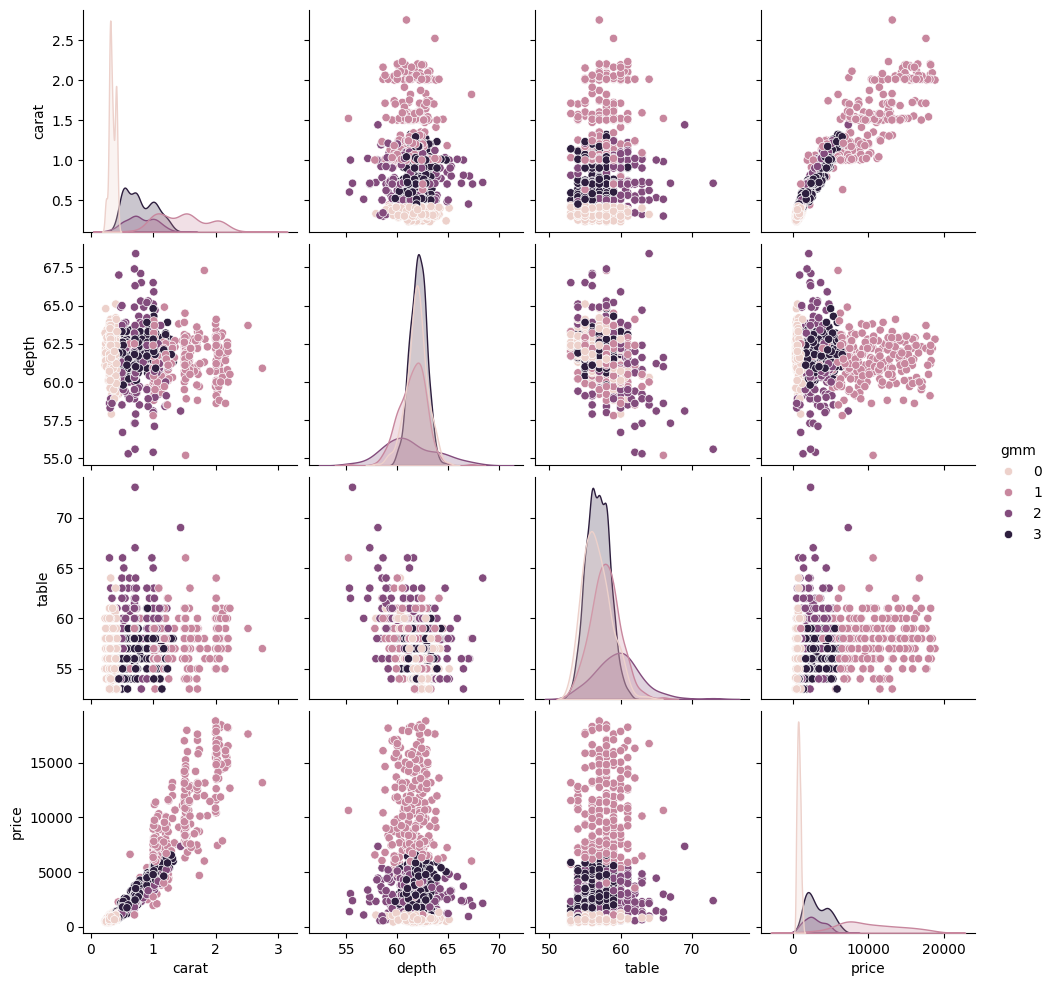

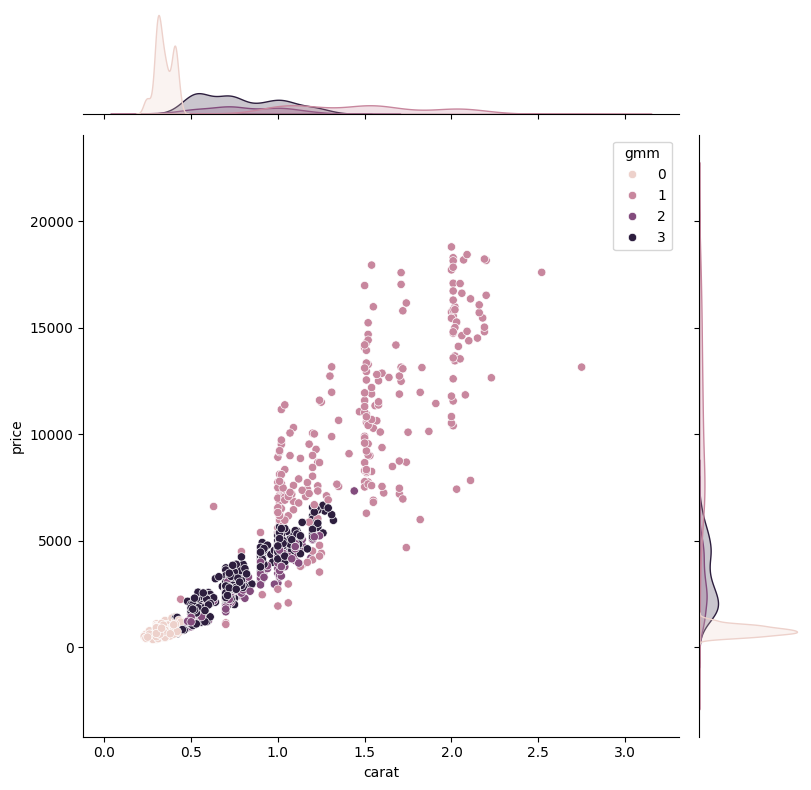

Without normalization the winner is G = 8


In [9]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) numeric columns and missing values
# I keep the 4 columns with numbers and check there are no empty values.
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']]
print(diamonds_num.isna().sum())
diamonds_num = diamonds_num.dropna()
print('Rows after dropna: {}'.format(diamonds_num.shape[0]))

# b) histogram of price with mean and mean +/- std
# Most diamonds are cheap and only a few are very expensive.
media_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()

fig = plt.figure(figsize=(10,6))
sns.histplot(diamonds_num['price'], bins=20)
plt.axvline(media_price, color="k", linestyle="--")
plt.axvline(media_price - std_price, color="r", linestyle="-")
plt.axvline(media_price + std_price, color="r", linestyle="-")
plt.show()

# c) normalize the 4 columns
# The price has very big numbers, so I scale the data.
diamonds_scaled = StandardScaler().fit_transform(diamonds_num)

# d) GMM from 1 to 8 components, keep the BIC of each one
# I try from 1 to 8 groups and keep the BIC of each one.
bic = []
n_components_range = range(1, 9)

for kG in n_components_range:
    gmm = mixture.GaussianMixture(n_components=kG, covariance_type='full', random_state=42).fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))
    print('G = {}  BIC = {}'.format(kG, round(bic[-1])))

fig = plt.figure(figsize=(10,6))
plt.plot(n_components_range, bic, marker='o')
plt.xlabel('Number of components')
plt.ylabel('BIC')
plt.show()

# e) best number of components = the lowest BIC
# The best number of groups is the one with the lowest BIC.
idx_winner = np.argmin(bic)
best_n = idx_winner + 1
print('...and the winner is GMM model G = {}'.format(best_n))

gmm = mixture.GaussianMixture(n_components=best_n, covariance_type='full', random_state=42).fit(diamonds_scaled)
gmm_labels = gmm.predict(diamonds_scaled)

# f) add the labels and make a pairplot + a jointplot
# I add the groups to the table and I make the plots.
diamonds_num = diamonds_num.copy()
diamonds_num['gmm'] = gmm_labels

sns.pairplot(diamonds_num, vars=['carat', 'depth', 'table', 'price'], hue='gmm')
plt.show()

sns.jointplot(x='carat', y='price', hue='gmm', data=diamonds_num, height=8)
plt.show()

# same BIC test without normalization (for question g)
bic_raw = []
for kG in n_components_range:
    gmm_raw = mixture.GaussianMixture(n_components=kG, covariance_type='full', random_state=42).fit(diamonds_num[['carat', 'depth', 'table', 'price']])
    bic_raw.append(gmm_raw.bic(diamonds_num[['carat', 'depth', 'table', 'price']]))
print('Without normalization the winner is G = {}'.format(np.argmin(bic_raw) + 1))

# g) interpretation
# With normalized data the lowest BIC is for 4 groups.
# But the BIC values for 4, 5, 6 groups are very close, so 4 is the best but not by much.
# In the pairplot the groups are mostly small and cheap diamonds vs big and expensive diamonds.
# The groups are not very separated: the price grows slowly with the carat, it is one big cloud.
# Only by looking at the plots I would not say 4 groups, maybe 2 (cheap and expensive).
# Without normalization the result is different (8 groups), because price has very big numbers
# and the model only looks at the price.